# CivicFlux — Hourly Junction Traffic Forecasting

**Research notebook · 13 sections · seed 42**

Inspired by the supplied 110-cell RTA notebook: inspect → visualize → clean → engineer → compare → tune → evaluate → explain → export. All outputs below are generated from the downloaded data. Read the limitations with the metrics; these are historical research models.

## 01. Problem definition

Predict **next-hour vehicle count at each junction**, in **vehicles/hour**, for **All four anonymous benchmark junctions**. The origin is immediately after the current observation becomes available; horizon is one regular interval. Publication delays are unknown, so deployment must shift the origin if reports arrive late.

Vehicle counts measure flow, not road speed or travel time. The benchmark does not supply a verified city, coordinates, lane capacity, incident reports, or a time zone. Network routing therefore requires additional measured edge data.

The holdout experiment is rolling one-step forecasting: earlier holdout observations may supply later lags after they become available. This is not a fixed-origin multi-step forecast.

### 1.1 Reproducibility and research budget

Imports and fixed seeds are explicit. No warning suppression, hidden package installation, or silent synthetic fallback is used.

In [1]:
from pathlib import Path
import sys, json, platform, importlib.metadata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import cross_validate, RandomizedSearchCV
from sklearn.inspection import permutation_importance
import joblib
ROOT = Path.cwd() if (Path.cwd() / 'civicflux_core.py').exists() else Path.cwd().parent
assert (ROOT / 'civicflux_core.py').exists(), 'Run from civicflux_ml or its notebooks directory'
sys.path.insert(0, str(ROOT))
from civicflux_core import *
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (11, 4), 'figure.dpi': 110})
SEED = 42
N_SPLITS = 3  # Expanding time folds; increase to five for a longer study.
N_SEARCH = 6  # Real searches are run; increase to 20+ for a larger compute budget.

KIND = 'traffic'
cfg = CONFIGS[KIND].copy()
OUT = ROOT / 'artifacts' / KIND
OUT.mkdir(parents=True, exist_ok=True)
print('Python', platform.python_version())

Python 3.13.5


## 02. Dataset introduction

Source: [Kaggle dataset](https://www.kaggle.com/datasets/fedesoriano/traffic-prediction-dataset). Read `DATASET_GUIDE.md` for API URLs, exact commands, licenses, schemas and quality limitations.

**Provenance:** Observational traffic benchmark as described by its publisher; anonymous junction geography and original sensor lineage remain unverified.

**File:** `traffic.csv`. The notebook inspects the complete downloaded file before selecting its modeling geography. Default scope is editable in `cfg['selected']`; changing it requires rerunning every cell. No unrelated sources are merged.

### 2.1 Load immutable source and fingerprint

The checksum identifies the exact bytes used. Downloaded CSVs are never overwritten.

In [2]:
source_path = ROOT / 'data' / 'raw' / cfg['file']
if not source_path.exists():
    raise FileNotFoundError('Run download_data.py or follow DATASET_GUIDE.md first')
raw = pd.read_csv(source_path)
fingerprint = sha256(source_path)
print('Source:', source_path.name, '\nSHA256:', fingerprint)
print('Actual rows and columns:', raw.shape)

Source: traffic.csv 
SHA256: 5d48fc91c8ca63a2d430140efb18750fe77828d058ec000e8644e819b20b1536
Actual rows and columns: (48120, 4)


### 2.2 Source coverage and unit contract

Coverage is measured from the file, rather than inferred from the dataset title.

In [3]:
display(pd.DataFrame({'rows': raw.groupby(cfg['entity']).size()}))
print('Timestamp range:', raw[cfg['time']].min(), 'to', raw[cfg['time']].max())
print('Target units:', cfg['unit'])
print('Timezone:', cfg['tz'] or 'unknown local civil time; do not convert to UTC')
print('Provenance:', cfg['provenance'])

,rows
Junction,
1,14592
2,14592
3,14592
4,4344


Timestamp range: 2015-11-01 00:00:00 to 2017-06-30 23:00:00
Target units: vehicles/hour
Timezone: unknown local civil time; do not convert to UTC
Provenance: observational benchmark; city, coordinates and timezone not supplied


## 03. Data inspection

Inspect structure, missingness, duplicate keys, numeric ranges and coverage before deciding how to model. Inspection is descriptive; model choices and thresholds must not use the final test outcomes.

### 3.1 First and last observations

Look for ordering, identifiers and unexpected formatting.

In [4]:
display(raw.head(8))
display(raw.tail(5))

,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041
5,2015-11-01 05:00:00,1,6,20151101051
6,2015-11-01 06:00:00,1,9,20151101061
7,2015-11-01 07:00:00,1,8,20151101071


,DateTime,Junction,Vehicles,ID
48115,2017-06-30 19:00:00,4,11,20170630194
48116,2017-06-30 20:00:00,4,30,20170630204
48117,2017-06-30 21:00:00,4,16,20170630214
48118,2017-06-30 22:00:00,4,22,20170630224
48119,2017-06-30 23:00:00,4,12,20170630234


### 3.2 Data types and cardinality

String dates are parsed later with a declared format.

In [5]:
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'unique':raw.nunique(), 'missing':raw.isna().sum()}))

,dtype,unique,missing
DateTime,object,14592,0
Junction,int64,4,0
Vehicles,int64,141,0
ID,int64,48120,0


### 3.3 Missingness table and plot

A blank measurement is not a zero concentration, zero traffic, or a dry day.

,count,percent
DateTime,0,0.0
Junction,0,0.0
Vehicles,0,0.0
ID,0,0.0


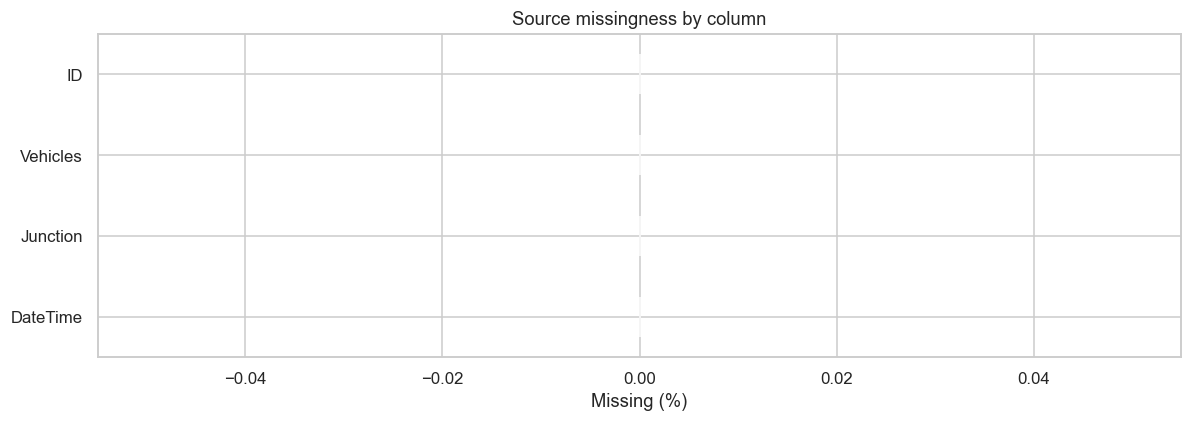

In [6]:
missing = pd.DataFrame({'count':raw.isna().sum(), 'percent':100*raw.isna().mean()})
display(missing.sort_values('percent', ascending=False))
missing['percent'].sort_values().plot.barh(title='Source missingness by column', xlabel='Missing (%)')
plt.tight_layout(); plt.show()

### 3.4 Duplicate audit

Exact rows can be removed once. Conflicting entity/timestamp keys cause a stop; averaging them would silently change the measurement definition.

In [7]:
print('Exact duplicate rows:', raw.duplicated().sum())
keys=[cfg['entity'],cfg['time']]
print('Repeated keys:', raw.duplicated(keys).sum())
display(raw.loc[raw.duplicated(keys,keep=False)].head(12))

Exact duplicate rows: 0
Repeated keys: 0


,DateTime,Junction,Vehicles,ID


### 3.5 Descriptive statistics and suspicious extremes

We inspect, not winsorize, genuine environmental peaks.

In [8]:
display(raw.describe(include='all').T)
display(raw.nlargest(10,cfg['value'])[[cfg['time'],cfg['entity'],cfg['value']]])

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
DateTime,48120,14592,2017-06-30 23:00:00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Junction,48120.0,NaN,NaN,NaN,2.180549,0.966955,1.0,1.0,2.0,3.0,4.0
Vehicles,48120.0,NaN,NaN,NaN,22.791334,20.750063,1.0,9.0,15.0,29.0,180.0
ID,48120.0,NaN,NaN,NaN,20163302501.220448,5944853.800152,20151101001.0,20160416019.0,20160930037.0,20170225162.25,20170630234.0


,DateTime,Junction,Vehicles
40723,2017-02-23 19:00:00,3,180
40724,2017-02-23 20:00:00,3,173
43574,2017-06-22 14:00:00,3,162
11299,2017-02-13 19:00:00,1,156
11294,2017-02-13 14:00:00,1,143
11298,2017-02-13 18:00:00,1,141
14010,2017-06-06 18:00:00,1,140
13643,2017-05-22 11:00:00,1,136
14011,2017-06-06 19:00:00,1,136
11297,2017-02-13 17:00:00,1,135


### 3.6 Timeline continuity

Per-entity interval differences reveal gaps and non-hourly/non-daily observations.

In [9]:
raw_times=pd.to_datetime(raw[cfg['time']], format=cfg['date_format'], errors='coerce')
spacing=pd.DataFrame({'entity':raw[cfg['entity']], 't':raw_times}).sort_values(['entity','t'])
display(spacing.groupby('entity').t.diff().value_counts().head(10).rename('interval_count'))

t
0 days 01:00:00    48116
Name: interval_count, dtype: int64

## 04. Exploratory analysis

To avoid designing features around the test set, analytical EDA below uses the earliest 60% of source timestamps. Full-source structural inspection above is retained for auditing. Extreme values stay visible on both ordinary and log scales.

In [10]:
cut = np.sort(raw_times.dropna().unique())[int(.6*raw_times.nunique())]
eda = raw.loc[raw_times < cut].copy()
eda['parsed_time'] = raw_times.loc[eda.index]
eda['month_eda'] = eda.parsed_time.dt.month
eda['weekday_eda'] = eda.parsed_time.dt.dayofweek
eda['hour_eda'] = eda.parsed_time.dt.hour
print('EDA only before',cut, '; rows',len(eda))

EDA only before 2016-10-30T19:00:00.000000000 ; rows 26265


### 4.1 Target distribution

Compare raw concentration/count/rainfall with log1p to make long tails visible without transforming the label.

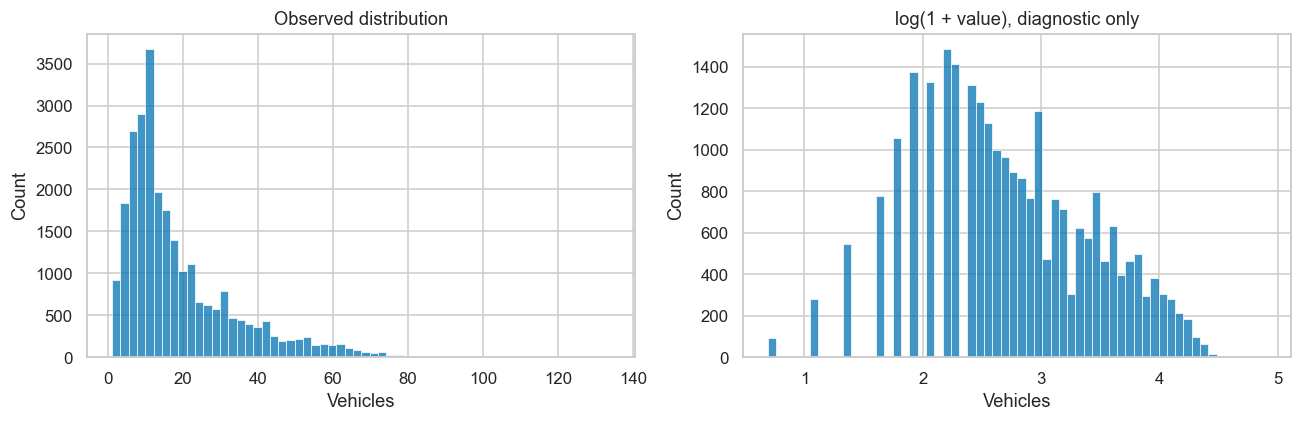

In [11]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(eda[cfg['value']],bins=60,ax=ax[0]); ax[0].set_title('Observed distribution')
sns.histplot(np.log1p(eda[cfg['value']].clip(lower=0)),bins=60,ax=ax[1]); ax[1].set_title('log(1 + value), diagnostic only')
plt.tight_layout(); plt.show()

### 4.2 Long-term changes

Monthly means are for descriptive visualization only; they never enter model features.

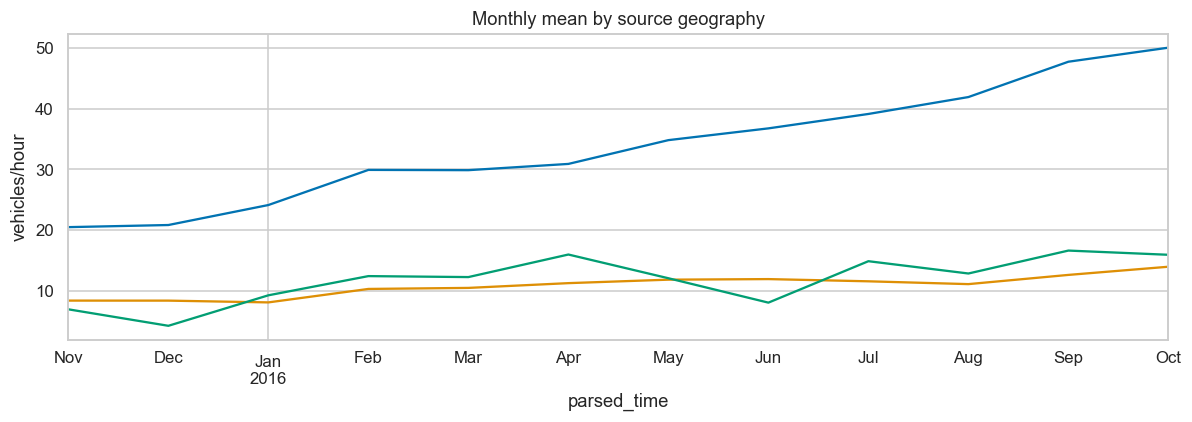

In [12]:
trend=eda.set_index('parsed_time').groupby(cfg['entity'])[cfg['value']].resample('MS').mean().unstack(0)
trend.plot(title='Monthly mean by source geography',ylabel=cfg['unit'],legend=False)
plt.tight_layout(); plt.show()

### 4.3 Seasonal distributions

Seasonality can motivate calendar features without using future outcomes.

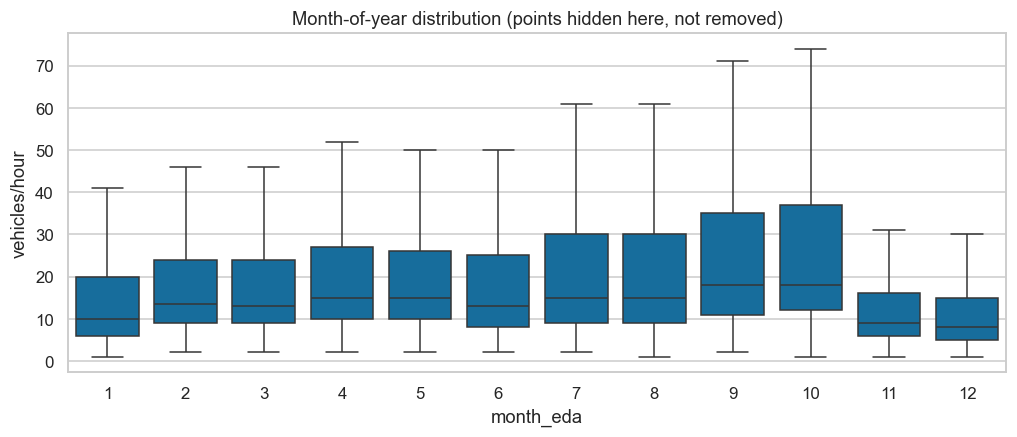

In [13]:
sns.boxplot(data=eda, x='month_eda', y=cfg['value'], showfliers=False)
plt.title('Month-of-year distribution (points hidden here, not removed)')
plt.ylabel(cfg['unit']); plt.show()

### 4.4 Weekly and diurnal patterns

Calendar comparisons are descriptive, not evidence of causation.

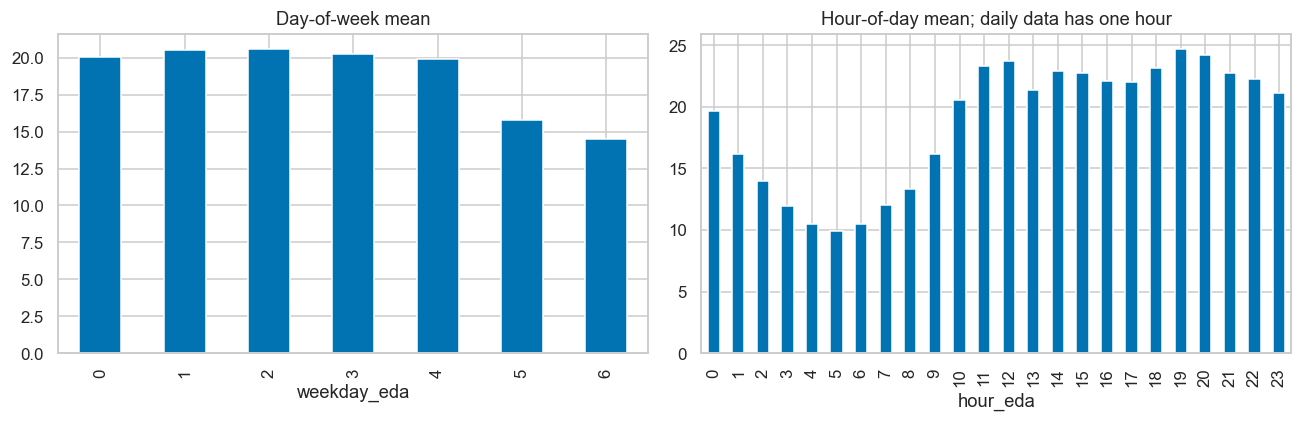

In [14]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
eda.groupby('weekday_eda')[cfg['value']].mean().plot.bar(ax=ax[0],title='Day-of-week mean')
eda.groupby('hour_eda')[cfg['value']].mean().plot.bar(ax=ax[1],title='Hour-of-day mean; daily data has one hour')
plt.tight_layout(); plt.show()

### 4.5 Geography and coverage

State means, city series and anonymous junctions represent different spatial resolutions.

,count,mean,median,max
Junction,,,,
1,8755,33.838264,31.0,106
2,8755,10.786522,10.0,40
3,8755,11.745060,9.0,134


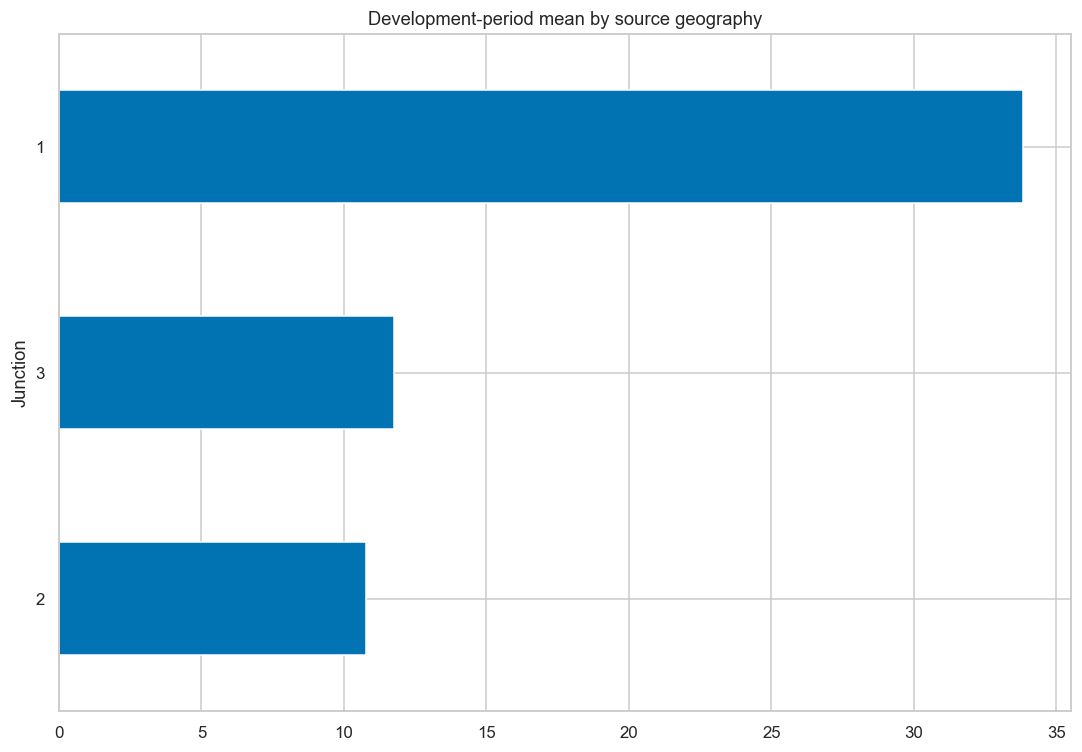

In [15]:
coverage=eda.groupby(cfg['entity'])[cfg['value']].agg(['count','mean','median','max'])
display(coverage)
coverage['mean'].sort_values().plot.barh(title='Development-period mean by source geography',figsize=(10,7))
plt.tight_layout(); plt.show()

### 4.6 Numeric associations

Identifiers and precomputed calendar fields can produce spurious correlations; this heatmap is not automatic feature selection.

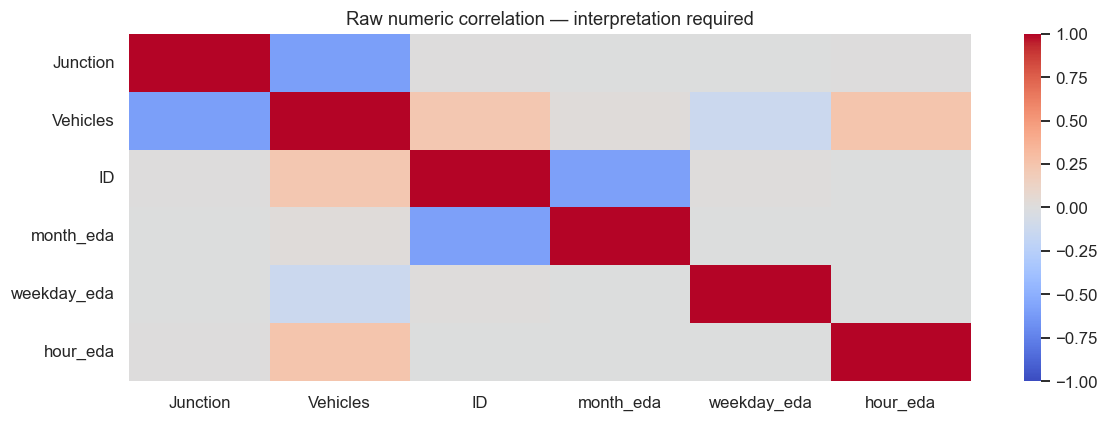

In [16]:
cols=eda.select_dtypes('number').columns
sns.heatmap(eda[cols].corr(),cmap='coolwarm',center=0,vmin=-1,vmax=1)
plt.title('Raw numeric correlation — interpretation required'); plt.tight_layout(); plt.show()

## 05. Preprocessing

`ID` encodes date/junction and is excluded. Junction is a categorical identity, not an ordinal numeric quantity. No speed, capacity or geographic join is inferred from count.

Policy: keep the first identical full row; reject conflicting entity-time records; parse timestamps exactly; retain nonnegative extremes; convert physically impossible negative target values to missing; insert absent grid intervals as missing. Labels are never imputed. Predictor medians and category encoding are learned only inside each training fold. There is no backward filling or interpolation.

For Indian rainfall/AQI we explicitly assume naive timestamps refer to Asia/Kolkata; this needs upstream confirmation. Traffic remains timezone-naive because its zone is undocumented. Daily rainfall is assumed available after the labeled day's total is reported; aggregation window and reporting latency require verification before live deployment.

### 5.1 Canonicalize and regularize

The shared implementation is also used by the exported raw-history prediction bundle.

In [17]:
history,audit=canonicalize(raw,cfg)
display(pd.Series(audit,name='audit'))
display(history.head())
(OUT/'cleaning_audit.json').write_text(json.dumps(audit,indent=2))

raw_rows                      48120
exact_duplicates_removed          0
invalid_timestamp_rows            0
negative_values_to_missing        0
selected_rows_before_grid     48120
regular_grid_rows             48120
unavailable_values                0
Name: audit, dtype: int64

,time,value,entity,source_missing
0,2015-11-01 00:00:00,15.0,1,0
1,2015-11-01 00:00:00,6.0,2,0
2,2015-11-01 00:00:00,9.0,3,0
3,2015-11-01 01:00:00,13.0,1,0
4,2015-11-01 01:00:00,6.0,2,0


217

### 5.2 Missingness after regularization

Missing labels remain missing. Median imputation later handles predictors without accessing future values.

Unavailable observed values: 0


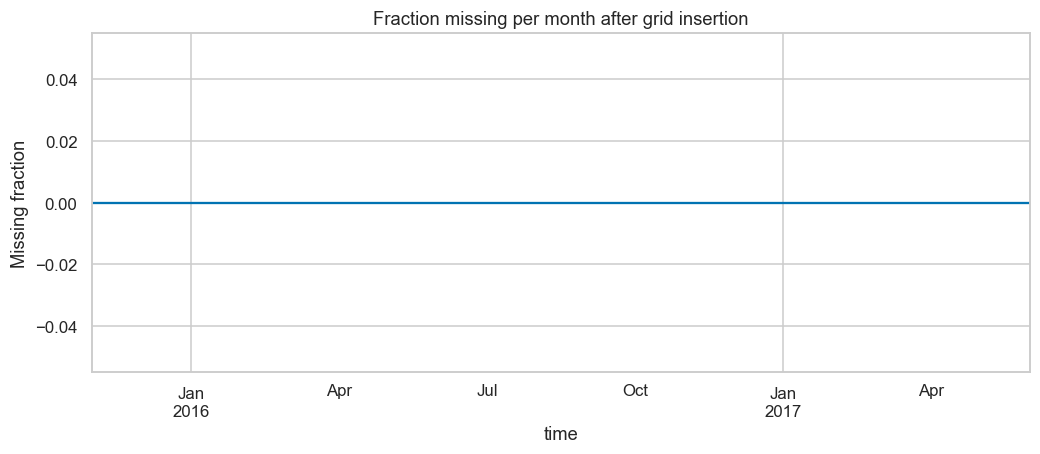

In [18]:
print('Unavailable observed values:',history.value.isna().sum())
history.set_index('time').source_missing.resample('MS').mean().plot(title='Fraction missing per month after grid insertion',ylabel='Missing fraction')
plt.show()

### 5.3 Outlier report without deletion

A train-period 99th percentile is diagnostic only. Heavy rainfall and pollution spikes may be the most important observations.

In [19]:
train_observed=history.loc[history.time < history.time.quantile(.6),'value']
extreme_cut=train_observed.quantile(.99)
print('Development 99th percentile:',extreme_cut)
print('Extremes retained:',history.value.gt(extreme_cut).sum())
assert history.value.dropna().ge(0).all()

Development 99th percentile: 73.0
Extremes retained: 2019


### 5.4 Geographic and temporal alignment

No cross-dataset join is performed. Exact entity ID and exact regular interval are required (spatial tolerance **zero across identities**, temporal tolerance **zero for target joins**). Delhi state rainfall is not localized catchment rain; city AQI coordinates are not station footprints; anonymous traffic junctions cannot be matched to Delhi. A future station-to-asset join must have verified coordinates, matching administrative codes and declared measurement footprints; provisional point matching could use ≤1 km and backward-only ≤1 hour, but these are unvalidated project assumptions, not applied here. State polygons cannot pass that point-radius rule.

## 06. Feature engineering

All lags are group-specific and measured on the complete regular grid. At origin t, the current observed value and windows ending at t are available. The label is the observation exactly one interval later. Calendar values describe that future interval and are known in advance.

### 6.1 Build auditable temporal features

Lag 1 means one complete earlier interval, not merely the previous available record.

In [20]:
frame=make_features(history,cfg)
# Start after the longest history window; never fill unavailable future labels.
first=history.groupby('entity').time.min()
warmup=pd.to_timedelta(max(cfg['lags']),unit='D' if cfg['freq']=='D' else 'h')
ready=frame.time >= frame.entity.map(first)+warmup
frame=frame.loc[ready & frame.target.notna()].reset_index(drop=True)
features=[c for c in frame if c not in ['time','target_time','target']]
assert not {'target','target_time','depth_m','aqi_category','ID','deviation'} & set(features)
display(frame.head()); print('Features:',features)

,time,entity,source_missing,current,lag_1,lag_2,lag_3,lag_24,lag_48,lag_168,...,hour,weekday,month,weekend,hour_sin,hour_cos,year_sin,year_cos,positive_fraction,target
0,2015-11-08 00:00:00,1,0,13.0,15.0,16.0,17.0,16.0,16.0,15.0,...,1,6,11,1,0.258819,0.965926,-0.79319,0.608975,1.0,16.0
1,2015-11-08 00:00:00,2,0,4.0,8.0,7.0,7.0,5.0,6.0,6.0,...,1,6,11,1,0.258819,0.965926,-0.79319,0.608975,1.0,3.0
2,2015-11-08 00:00:00,3,0,4.0,3.0,6.0,3.0,3.0,3.0,9.0,...,1,6,11,1,0.258819,0.965926,-0.79319,0.608975,1.0,6.0
3,2015-11-08 01:00:00,1,0,16.0,13.0,15.0,16.0,16.0,18.0,13.0,...,2,6,11,1,0.500000,0.866025,-0.79319,0.608975,1.0,11.0
4,2015-11-08 01:00:00,2,0,3.0,4.0,8.0,7.0,10.0,8.0,6.0,...,2,6,11,1,0.500000,0.866025,-0.79319,0.608975,1.0,7.0


Features: ['entity', 'source_missing', 'current', 'lag_1', 'lag_2', 'lag_3', 'lag_24', 'lag_48', 'lag_168', 'mean_3', 'std_3', 'coverage_3', 'mean_24', 'std_24', 'coverage_24', 'mean_168', 'std_168', 'coverage_168', 'change_1', 'hour', 'weekday', 'month', 'weekend', 'hour_sin', 'hour_cos', 'year_sin', 'year_cos', 'positive_fraction']


### 6.2 Feature dictionary

Each family has an explicit availability contract.

In [21]:
feature_dictionary=pd.DataFrame([
 ('current','Observation at t; available after reporting'),
 ('lag_k','Observed target k intervals before t'),
 ('mean_w / std_w','Trailing statistics through t; no future values'),
 ('coverage_w / source_missing','Availability quality at origin, not future quality'),
 ('calendar and cyclic','Known calendar of t+1'),
 ('positive_fraction','Trailing fraction positive, not an incident count'),
 ('entity','Exact state/city/junction identity')],columns=['family','definition'])
display(feature_dictionary)
feature_dictionary.to_csv(OUT/'feature_dictionary.csv',index=False)

,family,definition
0,current,Observation at t; available after reporting
1,lag_k,Observed target k intervals before t
2,mean_w / std_w,Trailing statistics through t; no future values
3,coverage_w / source_missing,"Availability quality at origin, not future qua..."
4,calendar and cyclic,Known calendar of t+1
5,positive_fraction,"Trailing fraction positive, not an incident count"
6,entity,Exact state/city/junction identity


### 6.3 Visualize the lag relationship

Use development rows only and sample deterministically for plotting.

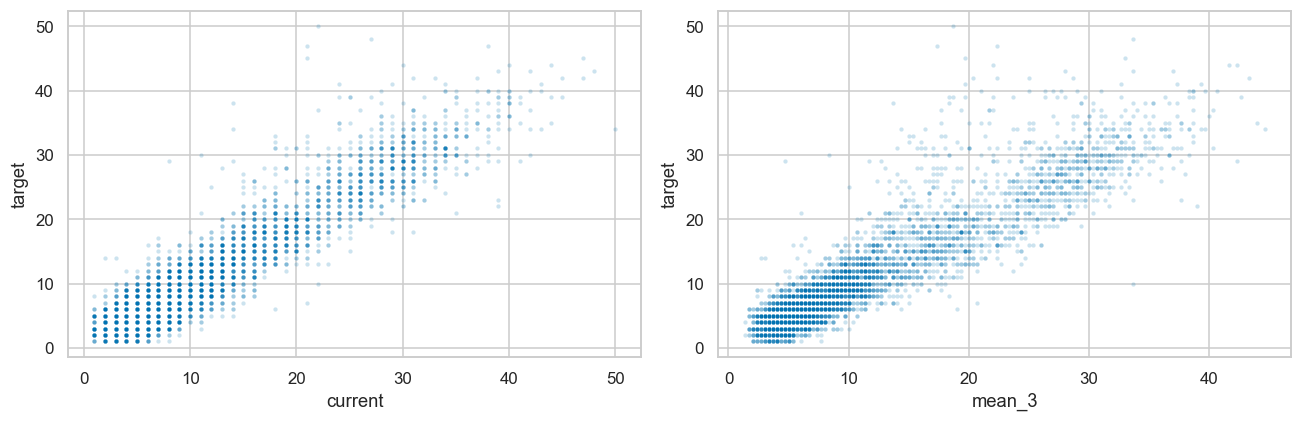

In [22]:
preview=frame[frame.time<frame.time.quantile(.6)].head(5000)
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.scatterplot(data=preview,x='current',y='target',alpha=.2,s=8,ax=ax[0])
sns.scatterplot(data=preview,x=f'mean_{cfg["windows"][0]}',y='target',alpha=.2,s=8,ax=ax[1])
plt.tight_layout(); plt.show()

### 6.4 Visualize trailing features

Smoothing changes the noise level; it must not change the information cutoff.

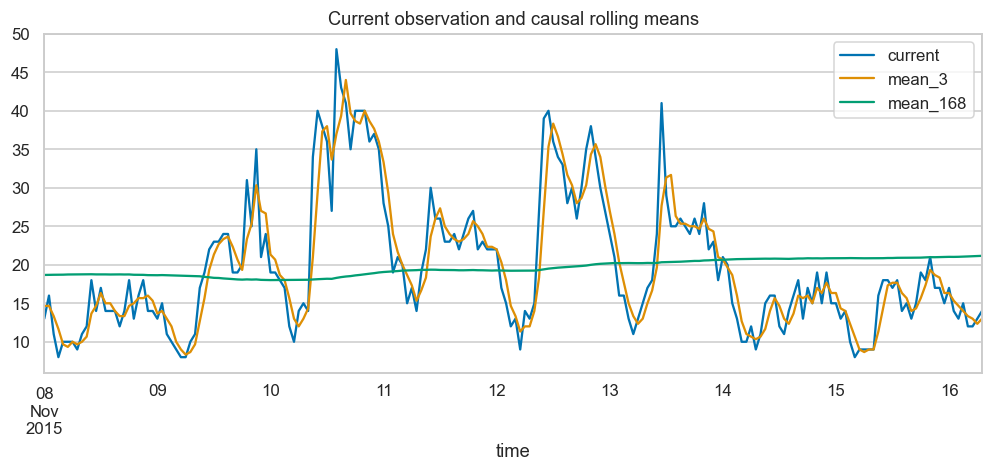

In [23]:
one=preview[preview.entity.eq(preview.entity.iloc[0])].head(200).set_index('time')
one[['current',f'mean_{cfg["windows"][0]}',f'mean_{cfg["windows"][-1]}']].plot(title='Current observation and causal rolling means')
plt.show()

### 6.5 Incident-history availability

These datasets do not contain verified incidents or report timestamps. Missing incident history is explicitly unavailable and excluded; zeros would invent evidence.

In [24]:
incident_counts=historical_incidents(frame[['entity','time']],None)
assert incident_counts.isna().all()
print('Historical incident count: unavailable; not included in model features')

Historical incident count: unavailable; not included in model features


### 6.6 Executable future-perturbation check

Changing a future observation must not change earlier predictor rows.

In [25]:
probe_time=history.time.sort_values().iloc[len(history)//2]
changed=history.copy()
changed.loc[changed.time>probe_time,'value']=999999
original_features=make_features(history,cfg,with_target=False)
changed_features=make_features(changed,cfg,with_target=False)
pd.testing.assert_frame_equal(original_features.loc[original_features.time<=probe_time],changed_features.loc[changed_features.time<=probe_time])
print('PASS: future measurements cannot change earlier features')

PASS: future measurements cannot change earlier features


## 07. Training strategy

Use 60% of unique timestamps for development, 20% for calibration and 20% for untouched final evaluation. Purge any training label that reaches a validation origin. Three expanding folds keep every location at a timestamp together. Select models by development CV MAE; never by final test scores. No SMOTE is appropriate for continuous forecasts. Rainfall imbalance is addressed through dry/wet and extreme slices, not fabricated targets.

### 7.1 Split once and document boundaries

The calibration period estimates uncertainty only; it is not used for candidate selection.

In [26]:
dev,cal,test=partition(frame)
Xdev,ydev=dev[features],dev.target
Xcal,ycal=cal[features],cal.target
Xtest,ytest=test[features],test.target
folds=temporal_folds(dev,N_SPLITS)
split_table=pd.DataFrame([{'split':name,'rows':len(z),'origin_start':z.time.min(),'origin_end':z.time.max(),'last_label':z.target_time.max()} for name,z in [('development',dev),('calibration',cal),('test',test)]])
display(split_table)
split_table.to_csv(OUT/'split_boundaries.csv',index=False)
assert dev.target_time.max()<cal.time.min()
assert cal.target_time.max()<test.time.min()

,split,rows,origin_start,origin_end,last_label
0,development,25956,2015-11-08 00:00:00,2016-11-02 11:00:00,2016-11-02 12:00:00
1,calibration,9941,2016-11-02 13:00:00,2017-03-02 16:00:00,2017-03-02 17:00:00
2,test,11540,2017-03-02 18:00:00,2017-06-30 22:00:00,2017-06-30 23:00:00


### 7.2 Plot temporal cross-validation

The gaps are horizon purges, not randomly held-out rows.

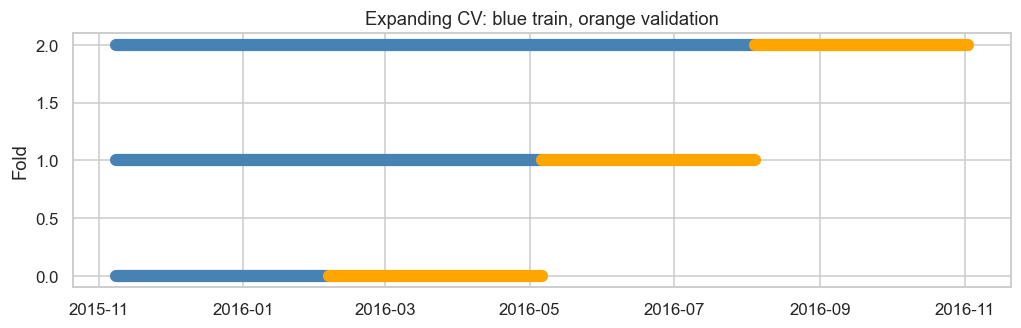

In [27]:
fig,ax=plt.subplots(figsize=(11,3))
for i,(tr,va) in enumerate(folds):
    ax.plot([dev.iloc[tr].time.min(),dev.iloc[tr].time.max()],[i,i],lw=8,color='steelblue')
    ax.plot([dev.iloc[va].time.min(),dev.iloc[va].time.max()],[i,i],lw=8,color='orange')
ax.set(title='Expanding CV: blue train, orange validation',ylabel='Fold'); plt.show()

### 7.3 Train-fold preprocessing

Numeric medians and missing indicators are fitted per fold. Categorical encoding ignores unseen entities. Only Ridge is scaled; trees are not.

In [28]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
numeric=[c for c in features if c!='entity']
def make_pipeline(model,scale=False):
    steps=[('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True))]
    if scale: steps.append(('scale',StandardScaler()))
    prep=ColumnTransformer([('num',Pipeline(steps),numeric),('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['entity'])])
    return Pipeline([('preprocess',prep),('model',model)])
models={
 'Persistence':BaselineRegressor('persistence'),
 'Seasonal mean':BaselineRegressor('seasonal'),
 'Ridge':make_pipeline(Ridge(alpha=10),scale=True),
 'Random Forest':make_pipeline(RandomForestRegressor(n_estimators=80,min_samples_leaf=5,max_depth=14,n_jobs=2,random_state=SEED)),
 'XGBoost':make_pipeline(XGBRegressor(n_estimators=120,max_depth=3,learning_rate=.05,subsample=.85,colsample_bytree=.9,objective='reg:squarederror',tree_method='hist',n_jobs=2,random_state=SEED))}
print('Candidates:',list(models))

Candidates: ['Persistence', 'Seasonal mean', 'Ridge', 'Random Forest', 'XGBoost']


## 08. Model experiments

The same folds and observations are used for every baseline and learned model. Persistence can be difficult to beat over one hour. Seasonal means are learned from training data only. The budget is deliberately finite and reported; this is a reproducible comparison, not a claim of globally optimal tuning.

### 8.1 Cross-validated model comparison

MAE is primary; RMSE and variability across time folds provide complementary evidence.

In [29]:
cv_rows=[]
for name,model in models.items():
    scores=cross_validate(model,Xdev,ydev,cv=folds,scoring={'mae':'neg_mean_absolute_error','rmse':'neg_root_mean_squared_error'},n_jobs=1,error_score='raise')
    for fold,(mae,rmse,seconds) in enumerate(zip(-scores['test_mae'],-scores['test_rmse'],scores['fit_time'])):
        cv_rows.append(dict(model=name,fold=fold,MAE=mae,RMSE=rmse,fit_seconds=seconds))
cv_details=pd.DataFrame(cv_rows)
cv_summary=cv_details.groupby('model').agg(MAE=('MAE','mean'),MAE_std=('MAE','std'),RMSE=('RMSE','mean'),fit_seconds=('fit_seconds','sum')).sort_values('MAE')
display(cv_summary)
cv_details.to_csv(OUT/'candidate_cv.csv',index=False)

,MAE,MAE_std,RMSE,fit_seconds
model,,,,
Random Forest,2.718087,0.075637,4.377489,6.656570
XGBoost,2.808227,0.126034,4.534691,0.183268
Ridge,2.887231,0.140470,4.405740,0.052320
Persistence,3.187959,0.247990,4.825744,0.004593
Seasonal mean,6.736637,1.445283,10.033501,0.003469


### 8.2 Compare error and stability

Large spread can indicate time-period sensitivity even when the average score is good.

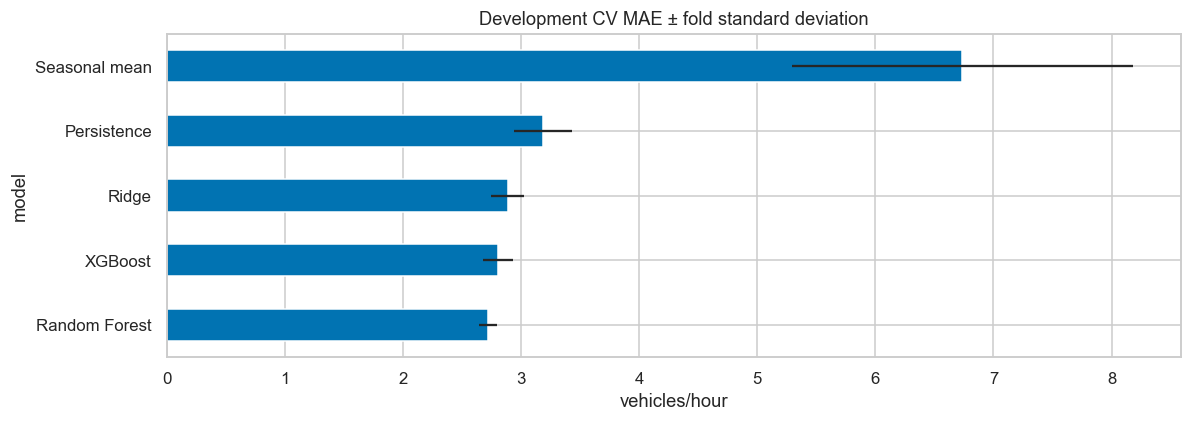

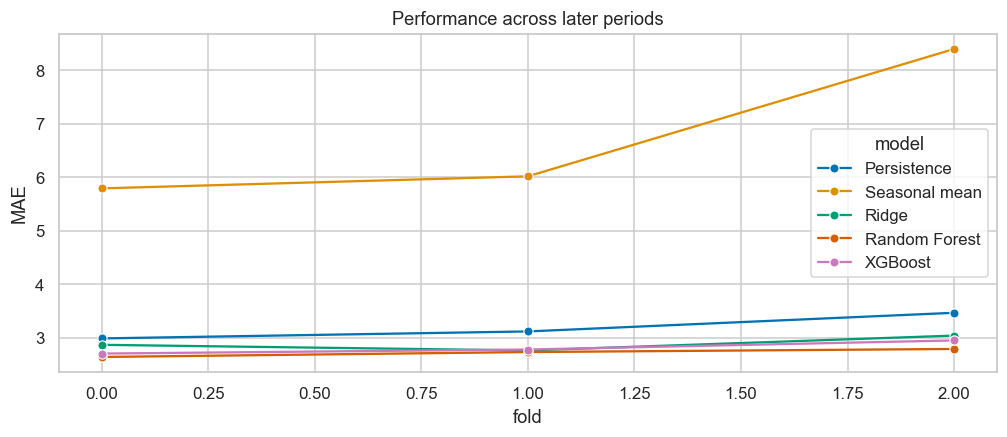

In [30]:
cv_summary.MAE.plot.barh(xerr=cv_summary.MAE_std,title='Development CV MAE ± fold standard deviation',xlabel=cfg['unit'])
plt.tight_layout(); plt.show()
sns.lineplot(data=cv_details,x='fold',y='MAE',hue='model',marker='o'); plt.title('Performance across later periods'); plt.show()

## 09. Hyperparameter tuning

Tune the two best learned candidates from development CV. Baselines remain eligible to win overall. RandomizedSearchCV refits preprocessing within every fold. Tuning CV scores are optimistic selection estimates; only section 10 provides a final generalization estimate.

### 9.1 Declare search spaces

Search sizes are visible and seeds fixed. No test-period early stopping is used.

In [31]:
spaces={
 'Ridge':{'model__alpha':[.1,1,10,100,1000,10000]},
 'Random Forest':{'model__n_estimators':[80,140],'model__max_depth':[8,14,None],'model__min_samples_leaf':[3,8,15],'model__max_features':[.7,1.]},
 'XGBoost':{'model__n_estimators':[80,140,220],'model__max_depth':[2,3,5],'model__learning_rate':[.03,.08,.15],'model__min_child_weight':[1,5,10],'model__subsample':[.7,1.],'model__reg_lambda':[1,5,15]}}
top=[name for name in cv_summary.index if name in spaces][:2]
print('Tune:',top,';',N_SEARCH,'settings each;',N_SPLITS,'folds')

Tune: ['Random Forest', 'XGBoost'] ; 6 settings each; 3 folds


### 9.2 Run searches and save every trial

Model selection does not consult calibration or final test labels.

In [32]:
searches={}
selection={name:float(-cv_summary.loc[name,'MAE']) for name in models}
for name in top:
    search=RandomizedSearchCV(models[name],spaces[name],n_iter=N_SEARCH,cv=folds,scoring='neg_mean_absolute_error',refit=True,random_state=SEED,n_jobs=1,error_score='raise',return_train_score=True)
    search.fit(Xdev,ydev)
    searches[name]=search
    selection[name+' tuned']=search.best_score_
    pd.DataFrame(search.cv_results_).to_csv(OUT/(name.replace(' ','_')+'_search.csv'),index=False)
    print(name,search.best_params_,'CV MAE',-search.best_score_)
selected_name=max(selection,key=selection.get)
final_model=searches[selected_name.removesuffix(' tuned')].best_estimator_ if selected_name.endswith(' tuned') else clone(models[selected_name]).fit(Xdev,ydev)
print('Locked winner:',selected_name)

Random Forest {'model__n_estimators': 80, 'model__min_samples_leaf': 8, 'model__max_features': 0.7, 'model__max_depth': None} CV MAE 2.7069389279046003


XGBoost {'model__subsample': 0.7, 'model__reg_lambda': 1, 'model__n_estimators': 140, 'model__min_child_weight': 10, 'model__max_depth': 3, 'model__learning_rate': 0.15} CV MAE 2.6636439286217937
Locked winner: XGBoost tuned


### 9.3 Tuning results and overfitting gap

Show the winning search trials, including train/validation divergence.

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
2,1,-2.706939,0.045025,-1.552454,"{'model__n_estimators': 80, 'model__min_sample..."
0,2,-2.728062,0.027305,-1.765349,"{'model__n_estimators': 140, 'model__min_sampl..."
1,3,-2.736882,0.071729,-1.230556,"{'model__n_estimators': 140, 'model__min_sampl..."
4,4,-2.744170,0.048433,-1.779161,"{'model__n_estimators': 80, 'model__min_sample..."
5,5,-2.765538,0.066857,-1.052439,"{'model__n_estimators': 140, 'model__min_sampl..."
3,6,-2.778444,0.073240,-1.055798,"{'model__n_estimators': 80, 'model__min_sample..."


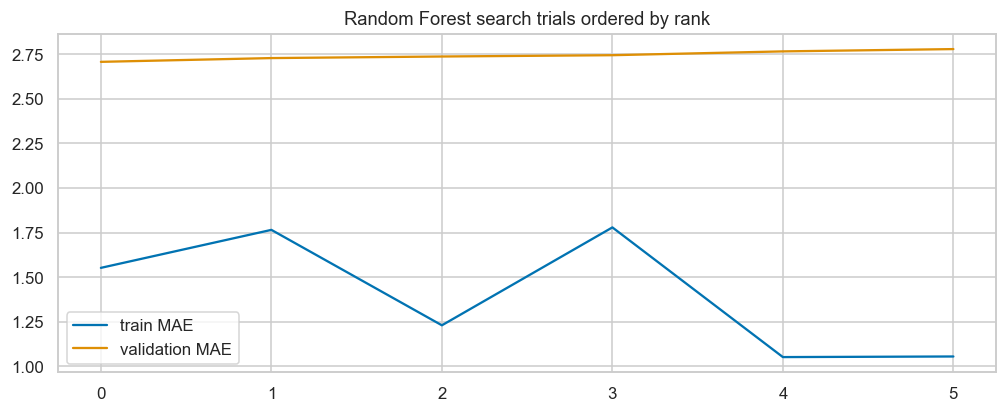

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
0,1,-2.663644,0.020522,-1.938256,"{'model__subsample': 0.7, 'model__reg_lambda':..."
2,2,-2.696273,0.101507,-1.877663,"{'model__subsample': 1.0, 'model__reg_lambda':..."
1,3,-2.748050,0.073583,-2.008393,"{'model__subsample': 0.7, 'model__reg_lambda':..."
4,4,-2.770683,0.040564,-2.123477,"{'model__subsample': 0.7, 'model__reg_lambda':..."
5,5,-2.898101,0.101925,-1.495930,"{'model__subsample': 1.0, 'model__reg_lambda':..."
3,6,-3.309266,0.400901,-1.537840,"{'model__subsample': 0.7, 'model__reg_lambda':..."


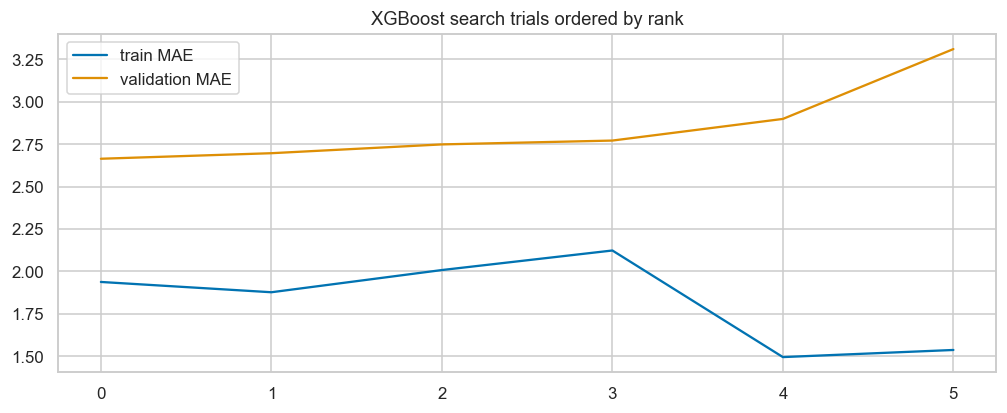

In [33]:
for name,s in searches.items():
    trials=pd.DataFrame(s.cv_results_).sort_values('rank_test_score')
    display(trials[['rank_test_score','mean_test_score','std_test_score','mean_train_score','params']].head(6))
    plt.plot(-trials.mean_train_score.to_numpy(),label='train MAE')
    plt.plot(-trials.mean_test_score.to_numpy(),label='validation MAE')
    plt.title(name+' search trials ordered by rank');plt.legend();plt.show()

### 9.4 Calibrate prediction intervals

Use the untouched calibration segment for a 90% absolute-residual interval. Time dependence means exchangeability is not guaranteed; report achieved coverage instead of promising nominal coverage.

In [34]:
cal_pred=np.maximum(0,final_model.predict(Xcal))
residual_abs=np.abs(ycal.to_numpy()-cal_pred)
q_level=min(1,np.ceil((len(residual_abs)+1)*.9)/len(residual_abs))
radius=float(np.quantile(residual_abs,q_level,method='higher'))
print('90% residual interval radius:',radius,cfg['unit'])

90% residual interval radius: 5.568780899047852 vehicles/hour


## 10. Final evaluation

The winner and uncertainty radius are now fixed. Evaluate the final test block once. Compare frozen persistence and seasonal baselines to contextualize performance, but do not change the selected model after seeing this section.

### 10.1 Test metrics and baseline skill

Predictions are clipped to the physical lower bound zero at serving and evaluation. CV uses raw predictions, so tiny differences may occur for linear candidates.

In [35]:
pred=np.maximum(0,final_model.predict(Xtest))
metrics=regression_metrics(ytest,pred)
comparison=[]
for name in ['Persistence','Seasonal mean']:
    baseline=clone(models[name]).fit(Xdev,ydev)
    comparison.append({'model':name,**regression_metrics(ytest,baseline.predict(Xtest))})
comparison.append({'model':selected_name,**metrics})
results=pd.DataFrame(comparison)
display(results)
metrics['MAE_skill_vs_persistence']=1-metrics['MAE']/max(results.iloc[0].MAE,1e-12)
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2))

,model,MAE,RMSE,R2,bias
0,Persistence,3.805633,5.720641,0.954100,-0.002340
1,Seasonal mean,16.067914,20.784077,0.394126,-9.799255
2,XGBoost tuned,3.249163,5.498183,0.957601,-0.958275


169

### 10.2 Forecast trace and intervals

Each point is a forecast from its preceding origin, not a forecast made once at the start of the entire test period.

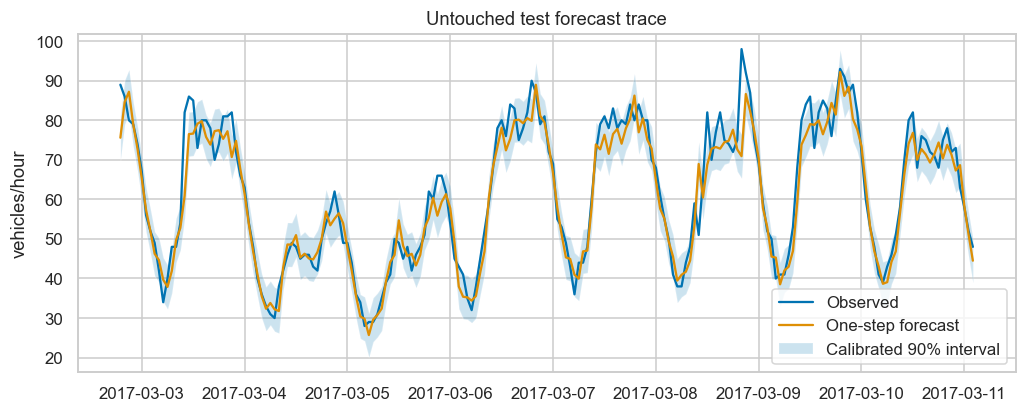

In [36]:
errors=test[['time','target_time','entity','target']].copy()
errors['prediction']=pred
errors['error']=pred-ytest.to_numpy()
errors['abs_error']=np.abs(errors.error)
errors['lower']=np.maximum(0,pred-radius);errors['upper']=pred+radius
errors.to_csv(OUT/'test_predictions.csv',index=False)
trace=errors[errors.entity.eq(errors.entity.iloc[0])].head(200)
plt.plot(trace.target_time,trace.target,label='Observed')
plt.plot(trace.target_time,trace.prediction,label='One-step forecast')
plt.fill_between(trace.target_time,trace.lower,trace.upper,alpha=.2,label='Calibrated 90% interval')
plt.legend();plt.ylabel(cfg['unit']);plt.title('Untouched test forecast trace');plt.show()

### 10.3 Residual diagnostics

Look for systematic bias, scale-dependent errors and serial dependence.

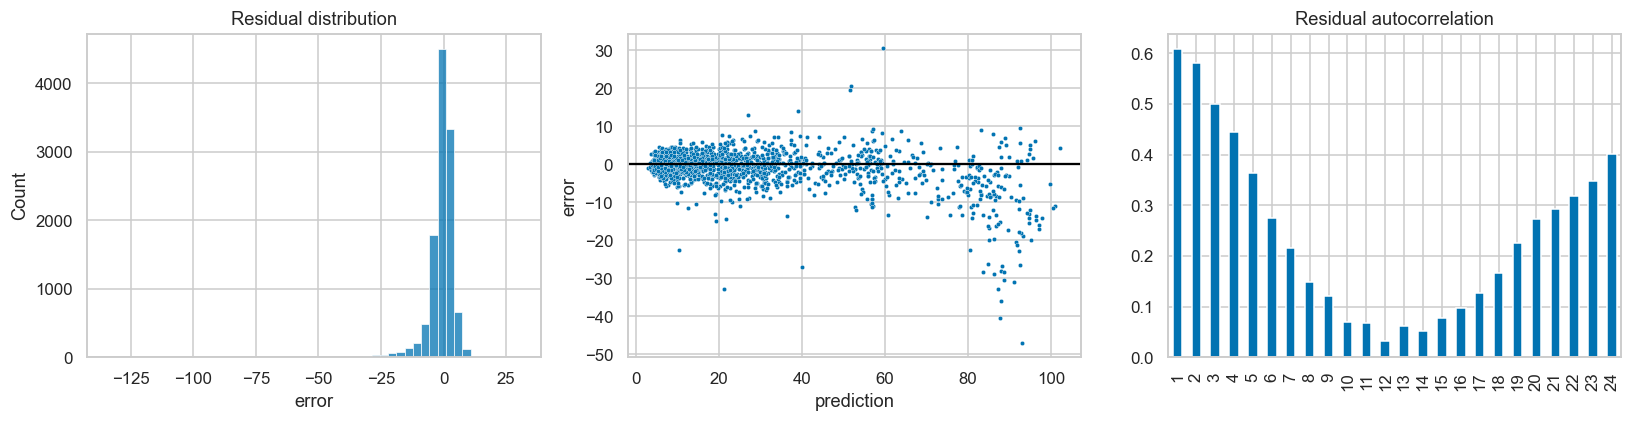

In [37]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
sns.histplot(errors.error,bins=50,ax=ax[0]);ax[0].set_title('Residual distribution')
sns.scatterplot(data=errors.iloc[::max(1,len(errors)//1500)],x='prediction',y='error',s=8,ax=ax[1]);ax[1].axhline(0,color='black')
entity_errors=errors[errors.entity.eq(errors.entity.iloc[0])].set_index('time').error.asfreq(cfg['freq'])
pd.Series({lag:entity_errors.autocorr(lag) for lag in range(1,25)}).plot.bar(ax=ax[2],title='Residual autocorrelation')
plt.tight_layout();plt.show()

### 10.4 Calibration and interval width

A wide interval can obtain coverage without being useful. Inspect both coverage and width.

Observed coverage: 0.8649913344887349 Mean width: 11.071997


,coverage,MAE,n
month,,,
3,0.894793,2.706171,2804
4,0.878819,2.947662,2880
5,0.864247,3.274488,2976
6,0.822917,4.053161,2880


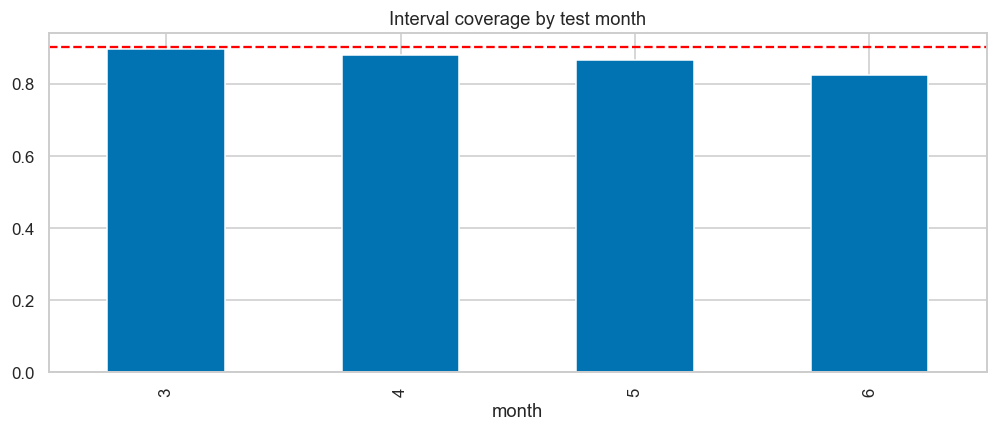

In [38]:
covered=(errors.target>=errors.lower)&(errors.target<=errors.upper)
print('Observed coverage:',covered.mean(),'Mean width:',(errors.upper-errors.lower).mean())
errors['covered']=covered
calibration=errors.assign(month=errors.target_time.dt.month).groupby('month').agg(coverage=('covered','mean'),MAE=('abs_error','mean'),n=('target','size'))
display(calibration)
calibration.coverage.plot.bar(title='Interval coverage by test month');plt.axhline(.9,color='red',ls='--');plt.show()

### 10.5 Error slices and worst cases

Upper-tail cutoff comes from development targets. These are audits, not post-test optimization.

In [39]:
cutoff=float(ydev.quantile(.9))
errors['slice']=np.where(errors.target>cutoff,'above development p90',np.where(errors.target==0,'zero','other'))
display(errors.groupby('slice').agg(n=('target','size'),MAE=('abs_error','mean'),bias=('error','mean')))
display(errors.groupby('entity').agg(n=('target','size'),MAE=('abs_error','mean')))
display(errors.nlargest(12,'abs_error'))

,n,MAE,bias
slice,,,
above development p90,2557,6.623186,-4.576380
other,8983,2.288752,0.071614


,n,MAE
entity,,
1,2885,5.778173
2,2885,2.443386
3,2885,2.925803
4,2885,1.849292


,time,target_time,entity,target,prediction,error,abs_error,lower,upper,covered,slice
10734,2017-06-22 13:00:00,2017-06-22 14:00:00,3,162.0,27.829601,-134.170399,134.170399,22.260820,33.398384,False,above development p90
9886,2017-06-13 17:00:00,2017-06-13 18:00:00,3,112.0,24.965326,-87.034674,87.034674,19.396545,30.534107,False,above development p90
2210,2017-03-25 18:00:00,2017-03-25 19:00:00,3,70.0,20.476889,-49.523111,49.523111,14.908108,26.045670,False,above development p90
7744,2017-05-22 10:00:00,2017-05-22 11:00:00,1,136.0,88.802971,-47.197029,47.197029,83.234192,94.371750,False,above development p90
9212,2017-06-06 17:00:00,2017-06-06 18:00:00,1,140.0,93.069839,-46.930161,46.930161,87.501060,98.638618,False,above development p90
9216,2017-06-06 18:00:00,2017-06-06 19:00:00,1,136.0,91.675674,-44.324326,44.324326,86.106895,97.244453,False,above development p90
9490,2017-06-09 14:00:00,2017-06-09 15:00:00,3,64.0,20.094164,-43.905836,43.905836,14.525383,25.662945,False,above development p90
8416,2017-05-29 10:00:00,2017-05-29 11:00:00,1,128.0,85.401733,-42.598267,42.598267,79.832954,90.970512,False,above development p90
7776,2017-05-22 18:00:00,2017-05-22 19:00:00,1,133.0,91.966927,-41.033073,41.033073,86.398148,97.535706,False,above development p90
11200,2017-06-27 10:00:00,2017-06-27 11:00:00,1,128.0,87.633263,-40.366737,40.366737,82.064484,93.202042,False,above development p90


## 11. Explainability

Permutation importance evaluates the locked model. Correlated lags can share importance; these associations are not causal. SHAP is shown for the selected tree or linear model on a small, documented sample. If the winning model is a baseline, the SHAP plot is explicitly an auxiliary tree explanation, never attributed to the winner.

### 11.1 Permutation importance

Use a deterministic calibration sample, not final test outcomes for feature selection.

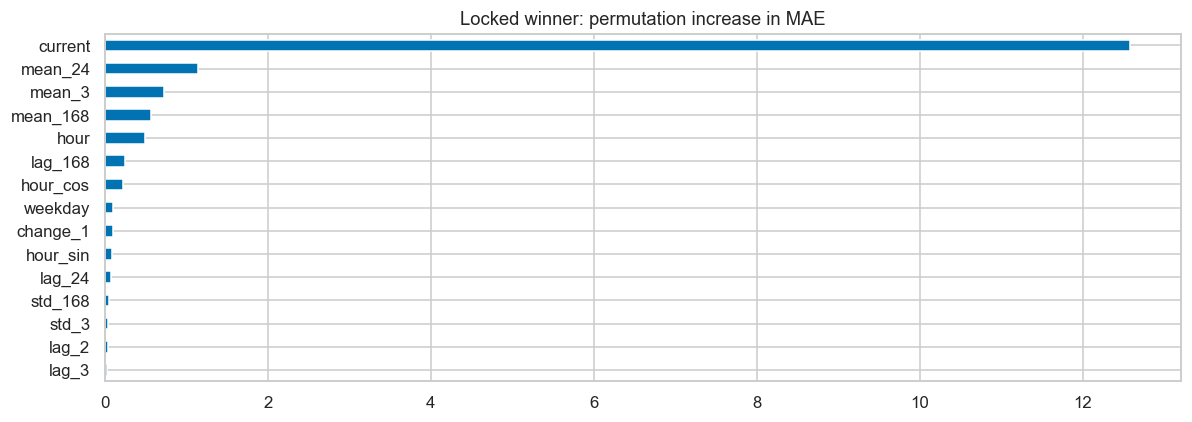

In [40]:
explain_X=Xcal.sample(min(200,len(Xcal)),random_state=SEED)
explain_y=ycal.loc[explain_X.index]
pi=permutation_importance(final_model,explain_X,explain_y,scoring='neg_mean_absolute_error',n_repeats=3,random_state=SEED,n_jobs=1)
importance=pd.Series(pi.importances_mean,index=features).sort_values()
importance.tail(15).plot.barh(title='Locked winner: permutation increase in MAE');plt.tight_layout();plt.show()
importance.to_csv(OUT/'permutation_importance.csv')

### 11.2 SHAP global explanation

Transform inputs with the exact fitted preprocessing. SHAP values explain model predictions, not real-world causes.

Explaining: XGBoost tuned


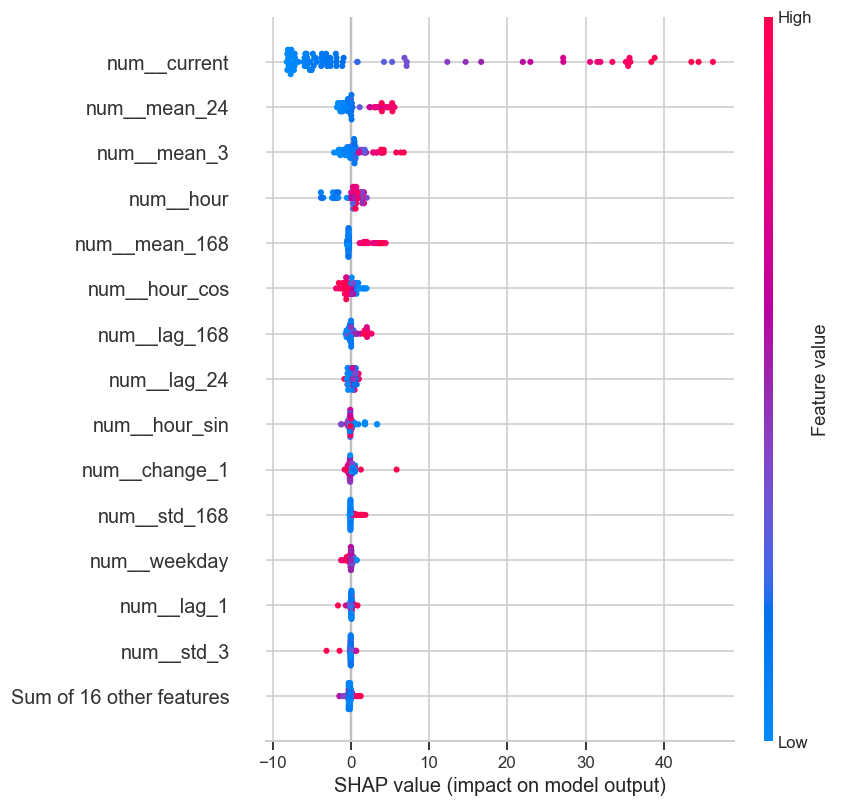

In [41]:
import shap
if hasattr(final_model,'named_steps') and isinstance(final_model.named_steps['model'],(XGBRegressor,RandomForestRegressor,Ridge)):
    shap_model=final_model;shap_label=selected_name
else:
    shap_model=clone(models['XGBoost']).fit(Xdev,ydev);shap_label='Auxiliary XGBoost (not the selected model)'
transformed=shap_model.named_steps['preprocess'].transform(explain_X.iloc[:80])
feature_names=shap_model.named_steps['preprocess'].get_feature_names_out()
if isinstance(shap_model.named_steps['model'],Ridge):
    background=shap_model.named_steps['preprocess'].transform(Xdev.sample(min(100,len(Xdev)),random_state=SEED))
    explanation=shap.LinearExplainer(shap_model.named_steps['model'],background)(transformed)
else:
    explanation=shap.TreeExplainer(shap_model.named_steps['model'])(transformed)
explanation.feature_names=list(feature_names)
print('Explaining:',shap_label)
shap.plots.beeswarm(explanation,max_display=15,show=False);plt.tight_layout();plt.show()

### 11.3 SHAP individual example

Inspect one representative row and its contributions in the prediction unit.

,entity,source_missing,current,lag_1,lag_2,lag_3,lag_24,lag_48,lag_168,mean_3,...,change_1,hour,weekday,month,weekend,hour_sin,hour_cos,year_sin,year_cos,positive_fraction
8772,4,0,9.0,7.0,10.0,7.0,10.0,9.0,8.0,8.666667,...,2.0,13,5,2,1,-0.258819,-0.965926,0.746588,0.665287,1.0


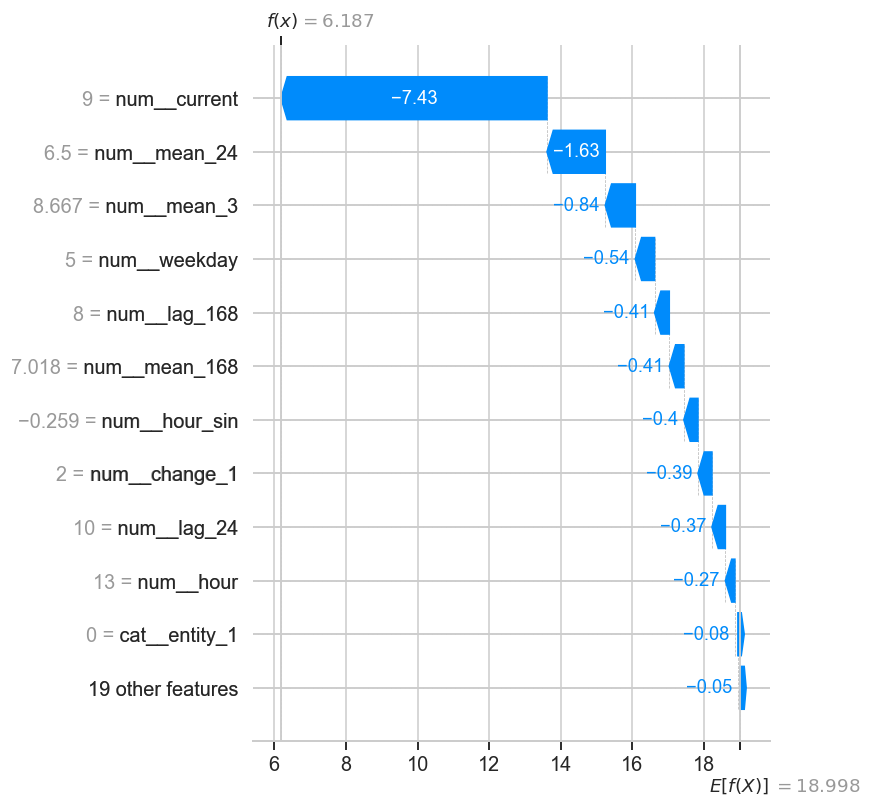

In [42]:
display(explain_X.iloc[[0]])
shap.plots.waterfall(explanation[0],max_display=12,show=False);plt.tight_layout();plt.show()

## 12. Model export

Export a full raw-history bundle plus a model card and ordered feature schema. The bundle includes the canonicalization/feature configuration and the fitted preprocessing/model; copy `civicflux_core.py` with the artifact. The input contract is a historical table in the downloaded schema, not an undocumented precomputed feature vector. Only load trusted joblib files.

### 12.1 Record metadata and package versions

Unverified source provenance and timezone assumptions travel with the model.

In [43]:
metadata={'task':KIND,'winner':selected_name,'source_url':'https://www.kaggle.com/datasets/'+SOURCES[KIND],'sha256':fingerprint,'units':cfg['unit'],'horizon':cfg['freq'],'timezone':cfg['tz'],'provenance':cfg['provenance'],'seed':SEED,'cv_folds':N_SPLITS,'search_iterations':N_SEARCH,'test_metrics':metrics,'interval_radius_90':radius,'operating_mode':'rolling one-step; current observation assumed available','deployment_status':'research; measurement lineage and reporting delays need validation','versions':{p:importlib.metadata.version(p) for p in ['pandas','numpy','scikit-learn','xgboost','shap','joblib']}}
schema={c:{'dtype':str(Xdev[c].dtype),'role':'feature'} for c in features}
(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2,default=str))
(OUT/'feature_schema.json').write_text(json.dumps(schema,indent=2))
bundle=ForecastBundle(final_model,cfg,features,radius,metadata)
joblib.dump(bundle,OUT/'pipeline.joblib')
print('Exported to',OUT)

Exported to /Users/jiyahooda/Documents/New project/civicflux_ml/artifacts/traffic


### 12.2 Reload and forecast beyond the last observation

This is a genuine next-interval forecast. It is separate from the evaluated historical holdout and has no known label yet.

In [44]:
loaded=joblib.load(OUT/'pipeline.joblib')
forecast=loaded.predict(raw)
pd.testing.assert_frame_equal(forecast,bundle.predict(raw))
display(forecast)
forecast.to_csv(OUT/'next_interval_forecast.csv',index=False)
print('PASS: serialized raw-history serving agrees with in-memory prediction')

,entity,time,target_time,prediction,lower_90,upper_90,source_missing
0,2,2017-06-30 23:00:00,2017-07-01,23.944773,18.375992,29.513554,0
1,3,2017-06-30 23:00:00,2017-07-01,32.815918,27.247137,38.384697,0
2,1,2017-06-30 23:00:00,2017-07-01,70.228096,64.659317,75.796875,0
3,4,2017-06-30 23:00:00,2017-07-01,13.145441,7.576660,18.714222,0


PASS: serialized raw-history serving agrees with in-memory prediction


## 13. CivicFlux integration

Emit a typed prediction with geography, horizon, units, uncertainty and provenance. The example policy is illustrative and has no automatic public-alert or dispatch action. Different variables are never silently added into one risk score. Routing requires verified road connectivity, travel times and capacities; OR-Tools/NetworkX are not required for these forecasting tasks.

### 13.1 Decision-engine payload

The engine can request review when uncertainty is wide. Thresholds below are examples, not validated operational limits.

In [45]:
payloads=[]
for r in forecast.itertuples():
    payload={'variable':{'rainfall':'rainfall_mm_day','aqi':'pm25_concentration','traffic':'vehicle_count_hour'}[KIND], 'geography':r.entity,'origin':str(r.time),'valid_at':str(r.target_time),'timezone':cfg['tz'] or 'unknown','prediction':float(r.prediction),'interval_90':[float(r.lower_90),float(r.upper_90)],'unit':cfg['unit'],'source_quality':cfg['provenance'],'current_observation_missing':bool(r.source_missing),'action':'human_review_required','research_only':True}
    payloads.append(payload)
print(json.dumps(payloads,indent=2))
(OUT/'civicflux_payload.json').write_text(json.dumps(payloads,indent=2))

[
  {
    "variable": "vehicle_count_hour",
    "geography": "2",
    "origin": "2017-06-30 23:00:00",
    "valid_at": "2017-07-01 00:00:00",
    "timezone": "unknown",
    "prediction": 23.944772720336914,
    "interval_90": [
      18.375991821289062,
      29.513553619384766
    ],
    "unit": "vehicles/hour",
    "source_quality": "observational benchmark; city, coordinates and timezone not supplied",
    "current_observation_missing": false,
    "action": "human_review_required",
    "research_only": true
  },
  {
    "variable": "vehicle_count_hour",
    "geography": "3",
    "origin": "2017-06-30 23:00:00",
    "valid_at": "2017-07-01 00:00:00",
    "timezone": "unknown",
    "prediction": 32.81591796875,
    "interval_90": [
      27.24713706970215,
      38.38469696044922
    ],
    "unit": "vehicles/hour",
    "source_quality": "observational benchmark; city, coordinates and timezone not supplied",
    "current_observation_missing": false,
    "action": "human_review_required

2056

### 13.2 Separate traffic-disruption scenario simulator

Capacity loss and demand pressure are hypothetical inputs. Predicted flow is not translated into measured road speed. These scenario rows never enter real-data model evaluation.

,junction,assumed_capacity_loss,forecast_demand_count,assumed_service_capacity,unserved_count_proxy,simulated
0,2,0.00,23.944773,35.917159,0.000000,True
1,2,0.25,23.944773,26.937869,0.000000,True
2,2,0.50,23.944773,17.958580,5.986193,True
3,3,0.00,32.815918,49.223877,0.000000,True
4,3,0.25,32.815918,36.917908,0.000000,True
5,3,0.50,32.815918,24.611938,8.203979,True
6,1,0.00,70.228096,105.342144,0.000000,True
7,1,0.25,70.228096,79.006608,0.000000,True
8,1,0.50,70.228096,52.671072,17.557024,True
9,4,0.00,13.145441,19.718162,0.000000,True


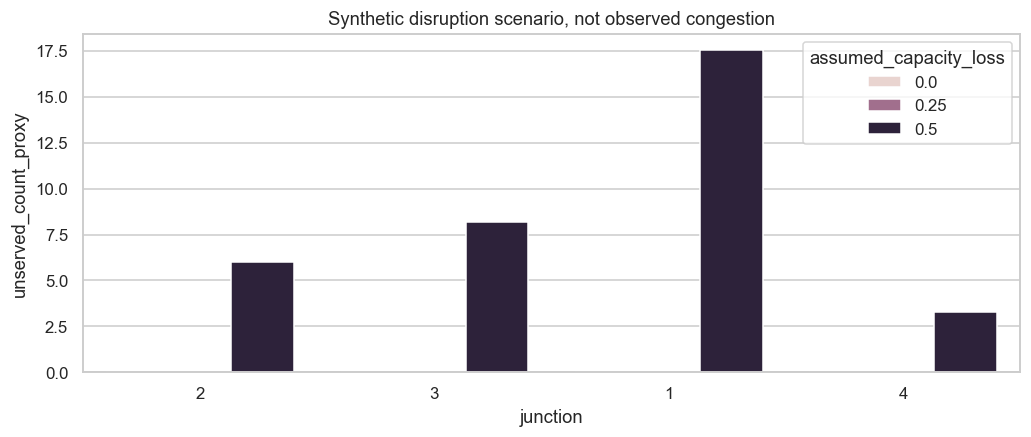

In [46]:
scenarios=[]
for r in forecast.itertuples():
    for loss in [0,.25,.50]:
        assumed_capacity=max(1,1.5*r.prediction)  # Explicit illustrative assumption, not measured.
        capacity=assumed_capacity*(1-loss)
        scenarios.append({'junction':r.entity,'assumed_capacity_loss':loss,'forecast_demand_count':r.prediction,'assumed_service_capacity':capacity,'unserved_count_proxy':max(0,r.prediction-capacity),'simulated':True})
disruption=pd.DataFrame(scenarios)
display(disruption)
sns.barplot(data=disruption,x='junction',y='unserved_count_proxy',hue='assumed_capacity_loss');plt.title('Synthetic disruption scenario, not observed congestion');plt.show()
disruption.to_csv(OUT/'synthetic_disruption_scenarios.csv',index=False)

### 13.3 Research conclusion and next validation

Read the CV winner, baseline skill, extreme-error slice and interval coverage together. Negative baseline skill means the learned procedure has not justified replacing persistence. These files do not establish causal effects or field readiness. Before deployment, verify source units/timezone/reporting delay, measure geographic representativeness, backtest with latency, validate on later data, and establish domain-specific decision thresholds. For multiple future horizons, fit separate horizon-specific targets and repeat the temporal purge; do not relabel one-step outputs as a multi-day forecast.